# Step 0: Data Preparation for SpatialGRN Tutorial

## Overview

This notebook prepares the input data for the **SpatialGRN** (Spatial Gene Regulatory Network) tutorial series.  
Starting from two large, pre-processed **AnnData** (`.h5ad`) objects — one for single-nucleus RNA-seq (snRNA-seq) and one for 10x Genomics Xenium spatial transcriptomics — we:

---

## Conda / Python Environment Setup

A minimal conda environment for **Tutorial_1** notebook in this tutorial series can be created with:

```bash
conda create -n spatialgrn python=3.10
conda activate spatialgrn

# Core single-cell / spatial packages
pip install scanpy anndata tangram-sc

# Visualisation & utilities
pip install matplotlib seaborn adjustText

# Jupyter support
pip install jupyterlab ipywidgets
```

> **Tip:** If you plan to run Tangram on a GPU (recommended for large datasets), install a CUDA-compatible PyTorch *before* installing `tangram-sc`.

---

## Data Requirements

| Input file | Description | Approx. size |
|---|---|---|
| `human_DG_snrna.h5ad` | Preprocessed snRNA-seq reference (9 856 nuclei × 36 601 genes) from the BICCN human dentate gyrus (DG) project. Contains cell-type annotations (`class`, `subclass`, `subtype`), multiple normalisation layers (`counts`, `logCPM`, `lognorm`), and dimensionality-reduction embeddings. | ~2 GB |
| `human_DG_xenium.h5ad` | Preprocessed Xenium spatial data (44 997 nuclei × 366 genes) for the same brain region. Contains spatial coordinates (`obsm['spatial']`), cell-type annotations, and count layers. | ~500 MB |

Both files are stored in the lab-shared directory and are loaded via absolute paths below. If you are running this notebook outside the original environment, update the paths accordingly.

---

## Table of Contents
1. [Imports](#Imports)
2. [Set Output Directory](#set-dir)
3. [Load Data](#1.-Load-data)
4. [check data](#2.-Subset-to-donor)


## Imports

We import the standard single-cell analysis stack (`scanpy`, `anndata`), visualisation libraries (`matplotlib`, `seaborn`), and general-purpose utilities (`numpy`, `pandas`, `os`, `pathlib`, `time`).  
Warnings are suppressed for cleaner notebook output.

In [5]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import scanpy as sc
import anndata as ad

import scanpy.external as sce

import os
from pathlib import Path
import time

# Inital setting for plot size
from matplotlib import rcParams

#FIGSIZE = (3, 3)
#rcParams["figure.figsize"] = FIGSIZE

import warnings
warnings.filterwarnings('ignore')

/sc/arion/projects/CommonMind/xuan/Anaconda3/25/envs/Py310R44/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/sc/arion/projects/CommonMind/xuan/Anaconda3/25/envs/Py310R44/lib/python3.10/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


## Set Output Directory

We define a `master_dir` where **all** outputs from this preparation step will be saved.  
The directory is created if it does not already exist, then set as the working directory so that subsequent `write_h5ad` calls use simple relative-style paths.

> **Note:** Changing the working directory inside a notebook is convenient for tutorials but should be used with care in production pipelines.

In [ ]:
master_dir = 'SpatialGRN/'

if not os.path.exists(master_dir):
    os.makedirs(master_dir)
    
os.chdir(master_dir)

## 1. Load Data

We load two **AnnData** objects from `.h5ad` files:  

- **snRNA-seq reference** — a deeply-sequenced single-nucleus dataset with comprehensive cell-type annotations. This will serve as the reference transcriptome for Tangram imputation in later notebooks.  
- **Xenium spatial data** — a targeted spatial transcriptomics dataset covering a panel of ~366 genes. It provides spatially resolved expression but at lower gene coverage than snRNA-seq.

### Why `.h5ad`?
The `.h5ad` (HDF5-backed AnnData) format is the standard interchange format in the Scanpy / scverse ecosystem. It stores the expression matrix together with cell/gene metadata, multiple normalisation layers, embeddings, and unstructured annotations in a single, self-contained file.

### 1.1 Define File Paths

The two source `.h5ad` files are referenced by their absolute paths on the shared storage.

In [12]:
file_rna = 'data/human_DG_snrna.h5ad'
file_xenium = 'data/human_DG_xenium.h5ad'

### 1.2 Load snRNA-seq Reference

Loading the full snRNA-seq reference — 229 523 nuclei across 36 601 genes.  
The object carries rich metadata in `obs` (cell-level), `var` (gene-level), `obsm` (embeddings), `uns` (colours), and multiple expression `layers`.

In [13]:
snrna = sc.read_h5ad(file_rna)
snrna

AnnData object with n_obs × n_vars = 9856 × 36601
    obs: 'class', 'subclass', 'subtype'
    layers: 'counts', 'logCPM'

In [ ]:
# 1.2b Load snATAC-

### 1.3 Load Xenium Spatial Data

Loading the Xenium spatial dataset — 707 184 nuclei across 366 targeted genes.  
Key annotations include spatial coordinates (`obsm['spatial']`), cell-type labels, and QC metadata.

In [14]:
xenium = sc.read_h5ad(file_xenium)
xenium

AnnData object with n_obs × n_vars = 44997 × 366
    obs: 'class', 'subclass', 'subtype'
    uns: 'subclass_colors'
    obsm: 'spatial'
    layers: 'counts', 'logCPM'

## Colour Palettes & Cell-Type Ordering

### Why This Matters
Consistent colour palettes and cell-type ordering across all figures ensure that:
- Readers can visually track the same cell type across different plots.
- Rare cell types are not hidden behind more abundant populations in scatter/spatial plots.

We load a **pre-defined colour palette CSV** that maps each `class`, `subclass`, and `subtype` label to a specific hex colour.

### Display the Subclass Palette

A quick sanity check — inspect the colour mapping for the `subclass` level.

In [15]:
pal_subclass = {
    'DG': '#9edae5','MC': '#03F757','CA3': '#F80229','CA1': '#0087e6','SUB': '#e6dccf','EC': '#FD8CC1',
    'IN_NR2F2': '#4E8975','IN_VIP': '#89C35C','IN_LAMP5': '#7BCCB5','IN_SST': '#728C00','IN_PVALB': '#B2C248',
    'IN_PVALB_CHC': '#008080','CR': '#3B9C9C','Micro': '#FFA62F','PVM': '#65404b','VLMC': '#B93B8F',
    'PC': '#E0B0FF','SMC': '#4E387E','Endo': '#8FB0FF','Astro': '#D2AF81','OPC': '#FED439','Oligo': '#D5E4A2'
}

In [16]:
pal_subclass

{'DG': '#9edae5',
 'MC': '#03F757',
 'CA3': '#F80229',
 'CA1': '#0087e6',
 'SUB': '#e6dccf',
 'EC': '#FD8CC1',
 'IN_NR2F2': '#4E8975',
 'IN_VIP': '#89C35C',
 'IN_LAMP5': '#7BCCB5',
 'IN_SST': '#728C00',
 'IN_PVALB': '#B2C248',
 'IN_PVALB_CHC': '#008080',
 'CR': '#3B9C9C',
 'Micro': '#FFA62F',
 'PVM': '#65404b',
 'VLMC': '#B93B8F',
 'PC': '#E0B0FF',
 'SMC': '#4E387E',
 'Endo': '#8FB0FF',
 'Astro': '#D2AF81',
 'OPC': '#FED439',
 'Oligo': '#D5E4A2'}

### Define Cell-Type Plotting Order & Helper Function

The helper function `ann_plot_ordered` reorders an AnnData object so that cells belonging to specific types are plotted last (i.e., on top).  
This makes rarer but biologically important populations (e.g., `CR`, `PVM`) visible rather than buried under large neuronal clusters.

We apply this ordering to the Xenium object and also set the subclass palette explicitly.

In [18]:
# define umap plot order by cell type
def ann_plot_ordered(
    adata,
    groupby,
    groupby_order # the group will plot by this order from top to bottom
):
    groupby_order.reverse()
    adata_tmp = adata.copy()
    adata_all = []
    for ct in groupby_order:
        adata_one = adata_tmp[adata_tmp.obs[groupby].isin([ct])]
        adata_all.append(adata_one)

    adata_all = sc.concat(adata_all)
    cat_type = pd.api.types.CategoricalDtype(categories=groupby_order, ordered=True)
    adata_all.obs[groupby] = adata_all.obs[groupby].astype(cat_type)
    return(adata_all)

# adjust umap legend text
from adjustText import adjust_text
import matplotlib.patheffects as pe


subclass_order_xenium = [
    'DG', 'MC','CA3','CA1',  'SUB', 'EC', 
    'IN_NR2F2', 'IN_VIP', 'IN_LAMP5', 'IN_SST','IN_PVALB','IN_PVALB_CHC', 'CR',
    'Micro','PVM', 
    'VLMC', 'PC','SMC', 'Endo', 
    'Astro',  'OPC', 'Oligo']

xenium = ann_plot_ordered(
    xenium,
    groupby = 'subclass',
    groupby_order =subclass_order_xenium
)

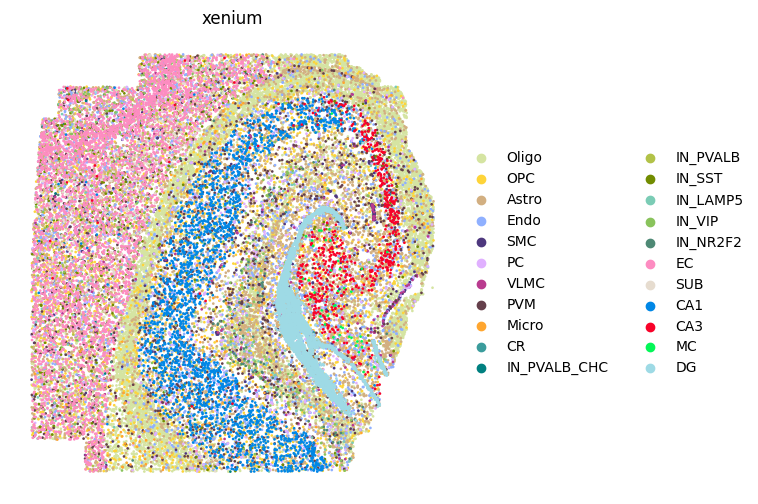

In [19]:

with plt.rc_context({"figure.figsize": (6, 6)}):
    sc.pl.spatial(
        xenium,
        color='subclass',
        size=6,
        spot_size=10,
        vmax = 150,
        frameon=False,
        title='xenium',
        palette=pal_subclass        
    )